# Final Project Recommendation Engine with Association Rules  

**Objective**  
Boréal Marché is a Québec online grocery retailer. Today its website shows the same list of “popular products” to
every customer. Management wants to replace that list with real recommendations based on what is already in
the shopping basket, and it wants to understand why each suggestion is made.
You are given one full year of transactions. You must deliver a complete system: from the raw file all the way to a
web application you could demonstrate in front of a client.

In [1]:
import pandas as pd
import time
import matplotlib.pyplot as plt
import tracemalloc
import gc
import json
from memory_profiler import memory_usage                               # tables (Dataframes)
from mlxtend.preprocessing import TransactionEncoder    # baskets -> True/False table
from mlxtend.frequent_patterns import apriori           # finds the frequent itemsets
from mlxtend.frequent_patterns import association_rules        # returns itemset into rulles

## Phase 1 - Loading and Prepare

In [2]:
## Loading tables
df_products = pd.read_csv('../data/products.csv')
tdf = pd.read_csv("../data/products.zip")

tdf.head(5)

,TransactionID,Date,CustomerID,Item
0,100000,2026-06-19,16595,Cidre de glace
1,100000,2026-06-19,16595,Couches
2,100000,2026-06-19,16595,Fromage cheddar
3,100000,2026-06-19,16595,Lingettes pour bébé
4,100000,2026-06-19,16595,Purée pour bébé


In [3]:

## Checking for duplicate rows
duplicate_count = tdf.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [4]:
## Creating matrix inital check and request
answer_matrix_phase_1={
    "Number of Baskets": None,
    "Number of Items": None,
    "Average basket size": None,
    "Time taken in seconds to build boolean table": None,
    "Memory used to build boolean table MB": None,
    "The 10 most frequent items": None,
    "The 5 rarest items": None,
    "Item is going to cause trouble": None,
    "Items recorded twice or more": None
}

In [5]:
## Creating baskets and calculating average number of items per basket
baskets = (tdf.groupby('TransactionID')['Item'].apply(lambda items: sorted(set(items))).tolist())
avg_items = tdf.groupby('TransactionID')['Item'].nunique().mean()
answer_matrix_phase_1["Average basket size"] = round(avg_items, 2)
answer_matrix_phase_1["Number of Baskets"] = len(baskets)
answer_matrix_phase_1["Number of Items"] = tdf['Item'].nunique()

In [6]:
## Building Boolean Table for Baskets

tracemalloc.start()
start = time.perf_counter()

te = TransactionEncoder()

transalated_basket  = te.fit(baskets).transform(baskets)
baskets_table = pd.DataFrame(transalated_basket, columns=te.columns_)
end = time.perf_counter()

answer_matrix_phase_1["Time taken in seconds to build boolean table"] = round(end - start, 2)
answer_matrix_phase_1["Memory used to build boolean table MB"] = round(tracemalloc.get_traced_memory()[1]/(1024**2), 2)
tracemalloc.stop()

In [7]:
## Looking for the most frequent and rarest items

ordered_baskets = baskets_table.mean(axis=0).sort_values(ascending=False)

answer_matrix_phase_1["The 10 most frequent items"] = ordered_baskets.head(10).to_dict()
answer_matrix_phase_1["The 5 rarest items"] = ordered_baskets.tail(5).to_dict()

display(answer_matrix_phase_1["The 10 most frequent items"])
display(answer_matrix_phase_1["The 5 rarest items"])

{'Sac réutilisable': 0.900026,
 'Biscuits': 0.161439,
 'Noix mélangées': 0.155189,
 "Beurre d'arachide": 0.153726,
 'Bière': 0.150468,
 'Savon à vaisselle': 0.14982,
 'Fromage cheddar': 0.143457,
 'Charbon de bois': 0.140561,
 'Papier hygiénique': 0.139758,
 'Céréales': 0.139198}

{'Safran': 0.000818,
 'Huile de truffe': 0.000817,
 'Caviar': 0.00081,
 'Vinaigre balsamique vieilli': 0.000779,
 'Foie gras': 0.000756}

In [8]:
## Checking items frequency distribution

ordered_baskets_df = pd.DataFrame(ordered_baskets, columns=['Frequency'])
ordered_baskets_df["nb_items_greater_or_equal_frequency"] = (
   ordered_baskets_df.groupby('Frequency')['Frequency']
   .transform('count')
   .cumsum()
)

ordered_baskets_df

,Frequency,nb_items_greater_or_equal_frequency
Sac réutilisable,0.900026,1
Biscuits,0.161439,2
Noix mélangées,0.155189,3
Beurre d'arachide,0.153726,4
Bière,0.150468,5
...,...,...
Safran,0.000818,94
Huile de truffe,0.000817,95
Caviar,0.000810,96
Vinaigre balsamique vieilli,0.000779,97


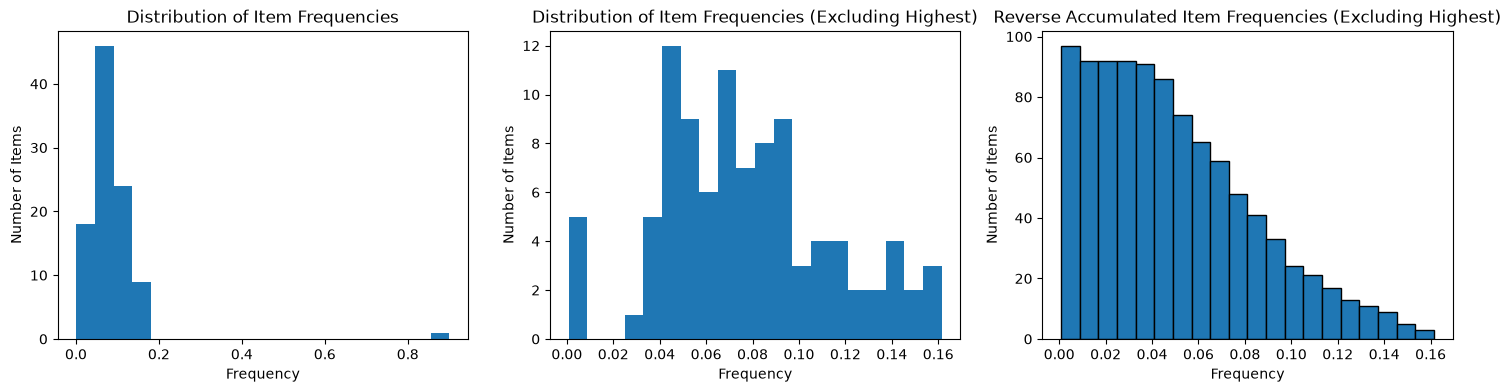

In [9]:
## Profiling possible supports

fig,axes = plt.subplots(1,3, figsize=(18,4))

frequencies_all = ordered_baskets
frequencies_less_highest = [f for f in frequencies_all if f < max(frequencies_all)]
axes[0].hist(frequencies_all, bins=20)
axes[0].set_xlabel('Frequency')
axes[0].set_ylabel('Number of Items')
axes[0].set_title('Distribution of Item Frequencies')

axes[1].hist(frequencies_less_highest, bins=20)
axes[1].set_xlabel('Frequency')
axes[1].set_ylabel('Number of Items')
axes[1].set_title('Distribution of Item Frequencies (Excluding Highest)')

axes[2].hist(
    [f for f in frequencies_all if f < max(frequencies_all)], 
    bins=20,
    cumulative=-1,
    edgecolor='black'
    )
axes[2].set_xlabel('Frequency')
axes[2].set_ylabel('Number of Items')
axes[2].set_title('Reverse Accumulated Item Frequencies (Excluding Highest)')

plt.show()

##### Visualization conclusion  
### Conclusion — Item Frequency Distribution

Most products have support below 10%, while *Sac réutilisable* is a clear outlier at 90%. Excluding this product reveals a more balanced distribution. We can also verifiy that there is a gap between the top 5 rarest items to the others.  The reverse cumulative chart shows that increasing the minimum support threshold reduces the number of eligible products, potentially excluding less frequent but meaningful associations.

In [10]:
answer_matrix_phase_1["Item is going to cause trouble"] ={
    "Sac réutilisable": ("\n"
        "       This item appears in 90% of the transactions.\n"
        "       It may generate association rules with high confidence due to its high frequency.\n"
        "       I intend to remove this item from the analysis to avoid misleading associations."
    )
}

In [11]:
## Checking for items recorded twice or more

items = tdf["Item"].dropna().unique()
products = df_products["Item"].dropna().unique()

check_items = [] 
for i in items:
    if i not in products:
        check_items.append(i)

print(check_items)

check_products = []
for p in products:
    if p not in items:
        check_products.append(p)

print(check_products)

if len(check_items) > 0:
    print(f"Invalid items found: {len(check_items)}")
if len(check_products) > 0:
    print(f"Invalid products found: {len(check_products)}")
else:
    print("No invalid items or products found.")

[]
[]
No invalid items or products found.


In [12]:
## Checking items with similar names

from difflib import SequenceMatcher
from itertools import combinations

products = tdf["Item"].dropna().unique()

similar_products = []

for p1, p2 in combinations(products, 2):
    similarity = SequenceMatcher(
        None,
        p1.lower().strip(),
        p2.lower().strip()
    ).ratio()

    if similarity >= 0.75:
        similar_products.append((p1, p2, similarity))

similar_products = sorted(
    similar_products,
    key=lambda x: x[2],
    reverse=True
)

for p1, p2, score in similar_products:
    print(f"{p1} | {p2} | Similarity: {score:.2%}")

In [13]:
answer_matrix_phase_1["Items recorded twice or more"] = "No items found recorded twice or more."

In [14]:
## Printing Answer Matrix Phase 1
sub_key = False
for key, value in answer_matrix_phase_1.items():
    if type(value) is dict:
        print(f"\n{key}:")
        for sub_key, sub_value in value.items():
            print(f"  {sub_key}: {sub_value}")
        sub_key = True
    else:
        if sub_key: print("\n")
        print(f"{key}: {value}")
        sub_key = False


Number of Baskets: 1000000
Number of Items: 98
Average basket size: 8.38
Time taken in seconds to build boolean table: 6.53
Memory used to build boolean table MB: 93.49

The 10 most frequent items:
  Sac réutilisable: 0.900026
  Biscuits: 0.161439
  Noix mélangées: 0.155189
  Beurre d'arachide: 0.153726
  Bière: 0.150468
  Savon à vaisselle: 0.14982
  Fromage cheddar: 0.143457
  Charbon de bois: 0.140561
  Papier hygiénique: 0.139758
  Céréales: 0.139198

The 5 rarest items:
  Safran: 0.000818
  Huile de truffe: 0.000817
  Caviar: 0.00081
  Vinaigre balsamique vieilli: 0.000779
  Foie gras: 0.000756

Item is going to cause trouble:
  Sac réutilisable: 
       This item appears in 90% of the transactions.
       It may generate association rules with high confidence due to its high frequency.
       I intend to remove this item from the analysis to avoid misleading associations.


Items recorded twice or more: No items found recorded twice or more.


### Phase 1 - Summary and Conclusion

#### Dataset Overview

The dataset contains **1,000,000 baskets** and **98 unique products**, with an average of **8.38 items per basket**.

| Metric | Value |
|---|---:|
| Total Baskets | 1,000,000 |
| Unique Products | 98 |
| Average Basket Size | 8.38 |
| Boolean Table Dimensions | 1,000,000 × 98 |
| Boolean Table Creation Time | 7.24 seconds |
| Boolean Table Memory Usage | 93.49 MB |

The Boolean transaction table was generated in **7.24 seconds**, consuming approximately **93.49 MB of memory**. This indicates that the dataset can be efficiently represented in memory for further association rule analysis.

#### Product Frequency Analysis

##### Top 10 Most Frequent Products

| Product | Support (%) |
|---|---:|
| Sac réutilisable | 90.00% |
| Biscuits | 16.14% |
| Noix mélangées | 15.52% |
| Beurre d'arachide | 15.37% |
| Bière | 15.05% |
| Savon à vaisselle | 14.98% |
| Fromage cheddar | 14.35% |
| Charbon de bois | 14.06% |
| Papier hygiénique | 13.98% |
| Céréales | 13.92% |

**Observation:** *Sac réutilisable* is by far the most frequent product, appearing in approximately 90% of baskets. The remaining top products have support values between 13.92% and 16.14%.

##### Top 5 Rarest Products

| Product | Support (%) |
|---|---:|
| Safran | 0.0818% |
| Huile de truffe | 0.0817% |
| Caviar | 0.0810% |
| Vinaigre balsamique vieilli | 0.0779% |
| Foie gras | 0.0756% |

**Observation:** These products appear in fewer than 0.1% of baskets. They may be excluded from frequent itemsets depending on the minimum support threshold selected during mining.

#### Potentially Problematic Product

**Identified Product:** Sac réutilisable

**Prediction:** This product appears in approximately 90% of transactions. Due to its high frequency, it may generate association rules with high confidence even when the relationship between products is weak. It appears to be a bag used to carry the purchased items, so it is unlikely to have a meaningful association with the products bought and may not provide useful insights for association rule mining.

#### Duplicate Product Verification

No products recorded twice or more were identified during the catalogue verification.

**Decision:** No product merging is required based on the current duplicate check.

#### Conclusion

The initial exploratory analysis shows that the dataset can be represented efficiently as a Boolean transaction table, requiring approximately **93.49 MB of memory** and **7.24 seconds** to build.

Two important characteristics were identified before mining:

- **Highly frequent products:** *Sac réutilisable* may be useless or a misleading to create an assocition rule.
- **Rare products:** Products such as *Foie gras* and *Safran* may not satisfy the minimum support threshold.


## Phase 2 — Mine the rules with Apriori

In [15]:
## Based on the charts visualizations, setting the minimum support equal 3% that is the frequency that exclude the 5 rarest items
## and keep all the other items
## Removing Sac réutilisable from the basket table
# baskets_table_new = baskets_table.copy().drop(columns=['Sac réutilisable'], errors='ignore')

# ordered_baskets_new = baskets_table_new.mean(axis=0).sort_values(ascending=False)

# ordered_baskets_new


#### Test at least four values of min_support and record: number of itemsets, number of rules, time taken, peak memory.

In [16]:
## Creating a mining function
def benchmark_rule(basket, min_support=0.05, min_confidence=0.6, low_memory=False):
    frequent_itemsets = apriori(basket, min_support=min_support, use_colnames=True, low_memory=low_memory)
    rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=min_confidence)

    return {
        "n_itemsets": len(frequent_itemsets),
        "n_rules": len(rules)

    }

In [ ]:
## Starting benchmark for min_support list [0.05, 0.02, 0.01, 0.005] and confidence list [0.6]
min_support_list = [0.05,0.02,0.01,0.005]
confidence_list = [0.7,0.6,0.5]
benchmark_results = []
for min_support in min_support_list:
    try:
            for min_confidence in confidence_list:
                start_time = time.perf_counter()
                peak_memory, result = memory_usage(
                    (benchmark_rule, (baskets_table,),{
                        "min_support": min_support, 
                        "min_confidence": min_confidence,
                        "low_memory": False
                        }
                        ), 
                        interval=0.1,
                        max_usage=True,
                        retval=True
                    )
                end_time = time.perf_counter()
                elapsed = end_time - start_time
                benchmark_results.append({
                    "min_support": min_support,
                    "min_confidence": min_confidence,
                    "n_itemsets": result["n_itemsets"],
                    "n_rules": result["n_rules"],
                    "execution_time": round(elapsed, 2),
                    "peak_memory_mib": round(peak_memory, 2)
                })
                print(
                    f"Support: {min_support}, "
                    f"Confidence: {min_confidence}, "
                    f"Itemsets: {result['n_itemsets']}, "
                    f"Rules: {result['n_rules']}, "
                    f"Time: {elapsed:.2f}s, "
                    f"Peak memory: {peak_memory:.2f} MiB"
                )
    except Exception as e:
        print(f"An error occurred for min_support={min_support}: {e}")

    if "result" in locals():
        del result
        gc.collect()

benchmark_df = pd.DataFrame(benchmark_results)
benchmark_df.to_json("../models/benchmark_results.json", orient="records")
display(benchmark_df)

Support: 0.05, Confidence: 0.7, Itemsets: 191, Rules: 153, Time: 38.48s, Peak memory: 8100.66 MiB
Support: 0.05, Confidence: 0.6, Itemsets: 191, Rules: 195, Time: 36.34s, Peak memory: 8100.91 MiB
Support: 0.05, Confidence: 0.5, Itemsets: 191, Rules: 242, Time: 35.67s, Peak memory: 8100.94 MiB
Support: 0.02, Confidence: 0.7, Itemsets: 658, Rules: 730, Time: 71.27s, Peak memory: 12928.59 MiB
Support: 0.02, Confidence: 0.6, Itemsets: 658, Rules: 1099, Time: 69.91s, Peak memory: 12929.18 MiB
Support: 0.02, Confidence: 0.5, Itemsets: 658, Rules: 1552, Time: 56.02s, Peak memory: 12929.70 MiB
Support: 0.01, Confidence: 0.7, Itemsets: 2267, Rules: 2177, Time: 196.80s, Peak memory: 19434.51 MiB
Support: 0.01, Confidence: 0.6, Itemsets: 2267, Rules: 3111, Time: 164.72s, Peak memory: 19136.88 MiB
Support: 0.01, Confidence: 0.5, Itemsets: 2267, Rules: 4325, Time: 172.86s, Peak memory: 20758.50 MiB
An error occurred for min_support=0.005: Unable to allocate 72.6 GiB for an array with shape (25975, 

,min_support,min_confidence,n_itemsets,n_rules,execution_time,peak_memory_mib
0,0.05,0.7,191,153,38.48,8100.66
1,0.05,0.6,191,195,36.34,8100.91
2,0.05,0.5,191,242,35.67,8100.94
3,0.02,0.7,658,730,71.27,12928.59
4,0.02,0.6,658,1099,69.91,12929.18
5,0.02,0.5,658,1552,56.02,12929.70
6,0.01,0.7,2267,2177,196.80,19434.51
7,0.01,0.6,2267,3111,164.72,19136.88
8,0.01,0.5,2267,4325,172.86,20758.50


In [18]:
## From the benchmark results, I decided to use a min_support of 0.02, min_confidence of 0.6, and lift greater than 1 for further analysis.


### Phase 2 - Summary and Conclusion

Apriori was tested with three support thresholds (0.05, 0.02, 0.01) and three confidence thresholds (0.5, 0.6, 0.7) to evaluate rule generation, execution time, and memory consumption.

#### Benchmark Results

| min_support | min_confidence | n_itemsets | n_rules | execution_time | peak_memory_mb |
|-------------|----------------|------------|---------|----------------|-----------------|
| 0.05 | 0.7 | 191 | 153 | 38.48 | 8100.66 |
| 0.05 | 0.6 | 191 | 195 | 36.34 | 8101.91 |
| 0.05 | 0.5 | 191 | 242 | 35.67 | 8101.94 |
| 0.02 | 0.7 | 658 | 730 | 71.27 | 12928.56 |
| 0.02 | 0.6 | 658 | 1099 | 69.91 | 12929.18 |
| 0.02 | 0.5 | 658 | 1552 | 56.02 | 12929.7 |
| 0.01 | 0.7 | 2267 | 2177 | 196.8 | 19434.15 |
| 0.01 | 0.6 | 2267 | 3111 | 164.72 | 19136.88 |
| 0.01 | 0.5 | 2267 | 4325 | 172.86 | 20758.5 |

#### Key Findings

- **Support:** Lower thresholds generate more itemsets and rules but increase processing time and memory consumption.
- **Confidence:** Lower thresholds increase the number of rules without affecting frequent itemsets.
- **Limit memory allocation:** At 0.5% minimum support, the Apriori algorithm failed attempting to allocate 72.6 GiB of memory.

#### Selected configuration for the Next Phase

- **Minimum support:** 0.02 (2%)
- **Minimum confidence:** 0.60 (60%)
- **Memory optimization:** `low_memory=False`
- **Lift filter:** Greater than 1, to retain positive associations.

This configuration generated **658 itemsets** and **1099 rules** in 69.91 seconds, using approximately 12.93 GB of peak process memory.

#### Conclusion

The results demonstrate the trade-off between discovering more association rules and increasing computational requirements. I decided to move to the nesxt steps using a minimum support of 2% and confidence of 60% provides, I think it will be a reasonable initial balance between performance and rule generation.

## Phase 3 — Evaluate the rules  

Based on the results of the previous phase, the following parameters were selected as a starting point for this section. These values are preliminary and may be adjusted at the end of this phase to achieve better results.

#### Starting rules and configuration

- **Minimum support:** 0.02 (2%)
- **Minimum confidence:** 0.60 (60%)
- **Memory optimization:** `low_memory=False`
- **Lift filter:** Greater than 1, to retain positive associations.

#### Define support, confidence and lift in one plain sentence each  
- **Support:** How frequently an itemset appears in all basket.
- **Confidence:** It can be interpreted as the frequency, how often, customers buy an item since they have alreay bought other items.
- **Lift:** How strong two or set of items are associeted to each other compared to a random choice. 

In [19]:
## Generating frequent itemsets with minimum support of 0.02

frequent_itemsets = apriori(baskets_table,
                            min_support=0.02,
                            use_colnames=True,
                            low_memory=False
                            )
frequent_itemsets['size'] = frequent_itemsets['itemsets'].apply(len) # apply(len) = length of each set



In [20]:
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.6)

rules['antecedents'] = rules['antecedents'].apply(lambda s: ', '.join(list(s)))
rules['consequents'] = rules['consequents'].apply(lambda s: ', '.join(list(s)))
rules.sort_values(by='confidence', ascending=False, inplace=True)

#### Sort the simple rules (one item on each side) by confidence and show the top 10.

In [21]:
## print top 10 highest confidence
cols = ['antecedents', 'consequents', 'antecedent support', 'consequent support', 'support', 'confidence', 'lift']
print("Top 10 highest confidence rules\n")
top10_confidence_rules = rules[cols].head(10).reset_index(drop=True)
top10_confidence_rules

Top 10 highest confidence rules



,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,"Bière, Ketchup, Pain à hamburger, Steak de boeuf",Charbon de bois,0.020151,0.140561,0.020151,1.000000,7.114349
1,"Pain à hamburger, Ketchup, Saucisses, Steak de...",Charbon de bois,0.021318,0.140561,0.021318,1.000000,7.114349
2,"Sauce tomate, Ail, Parmesan râpé",Pâtes alimentaires,0.035007,0.134353,0.035006,0.999971,7.442866
3,"Sauce tomate, Sac réutilisable, Ail, Parmesan ...",Pâtes alimentaires,0.031524,0.134353,0.031523,0.999968,7.442843
4,"Sauce BBQ, Sac réutilisable, Saucisses, Steak ...",Charbon de bois,0.022440,0.140561,0.022439,0.999955,7.114032
5,"Sauce BBQ, Ketchup, Steak de boeuf",Charbon de bois,0.027230,0.140561,0.027228,0.999927,7.113826
6,"Pain à hamburger, Ketchup, Sac réutilisable, S...",Charbon de bois,0.026605,0.140561,0.026603,0.999925,7.113814
7,"Sauce BBQ, Saucisses, Steak de boeuf",Charbon de bois,0.024893,0.140561,0.024891,0.999920,7.113777
8,"Sauce BBQ, Ketchup, Sac réutilisable, Steak de...",Charbon de bois,0.024598,0.140561,0.024596,0.999919,7.113770
9,"Pain à hamburger, Saucisses, Steak de boeuf",Charbon de bois,0.035164,0.140561,0.035161,0.999915,7.113742


#### Sort the same rules by lift and show the top 10.

In [22]:
## print top 10 highest lift
rules.sort_values(by='lift', ascending=False, inplace=True)
top10_lift_rules = rules[cols].head(10).reset_index(drop=True)
print("Top 10 highest lift rules\n")    
top10_lift_rules

Top 10 highest lift rules



,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,"Sauce soya, Algues nori","Sac réutilisable, Riz à sushi",0.036130,0.075251,0.032275,0.893302,11.870965
1,"Frites surgelées, Sauce à poutine","Sac réutilisable, Fromage en grains",0.034443,0.075214,0.030732,0.892257,11.862908
2,"Frites surgelées, Sauce à poutine",Fromage en grains,0.034443,0.083468,0.034102,0.990100,11.862026
3,"Sac réutilisable, Frites surgelées, Sauce à po...",Fromage en grains,0.031049,0.083468,0.030732,0.989790,11.858321
4,"Sac réutilisable, Sauce soya, Algues nori",Riz à sushi,0.032565,0.083645,0.032275,0.991095,11.848822
5,"Sauce soya, Algues nori",Riz à sushi,0.036130,0.083645,0.035808,0.991088,11.848739
6,"Sac réutilisable, Gingembre mariné, Algues nori",Riz à sushi,0.026987,0.083645,0.026681,0.988661,11.819729
7,"Gingembre mariné, Algues nori",Riz à sushi,0.030032,0.083645,0.029684,0.988412,11.816754
8,"Avocat, Algues nori","Sac réutilisable, Riz à sushi",0.023647,0.075251,0.021026,0.889161,11.815942
9,"Wasabi, Algues nori",Riz à sushi,0.027686,0.083645,0.027347,0.987756,11.808901


#### Sort the same rules by consequent support and show the top 10.

In [23]:
## Checking consequnet support itemset with 'Sac réutilisable'

rules[rules['consequent support']>=0.9][cols].sort_values(by="lift", ascending=False).head(10).reset_index(drop=True)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,"Bière, Saucisses, Steak de boeuf",Sac réutilisable,0.026975,0.900026,0.024379,0.903763,1.004152
1,"Bière, Charbon de bois, Saucisses, Steak de boeuf",Sac réutilisable,0.026942,0.900026,0.024349,0.903756,1.004145
2,"Sauce BBQ, Ketchup, Steak de boeuf",Sac réutilisable,0.027230,0.900026,0.024598,0.903342,1.003684
3,"Sauce BBQ, Ketchup, Charbon de bois, Steak de ...",Sac réutilisable,0.027228,0.900026,0.024596,0.903335,1.003676
4,"Sauce BBQ, Relish",Sac réutilisable,0.022282,0.900026,0.020121,0.903016,1.003322
5,"Avocat, Riz à sushi, Algues nori",Sac réutilisable,0.023292,0.900026,0.021026,0.902713,1.002986
6,"Bière, Steak de boeuf",Sac réutilisable,0.049828,0.900026,0.044978,0.902665,1.002932
7,Concombre,Sac réutilisable,0.069634,0.900026,0.062853,0.902619,1.002881
8,"Avocat, Algues nori",Sac réutilisable,0.023647,0.900026,0.021342,0.902525,1.002776
9,"Bière, Charbon de bois, Steak de boeuf",Sac réutilisable,0.048445,0.900026,0.043715,0.902364,1.002597


In [24]:
rules[rules['antecedent support']>=0.9][cols].sort_values(by="lift", ascending=False)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift


#### Compare the three lists and explain the difference.  

Comparing the three top-10 lists—highest confidence, highest lift, and highest consequent support—confirms that high confidence and support do not necessarily indicate a strong association. This is evident for **Sac réutilisable**, which appears in approximately 90% of baskets. As we can deduce from the equation below, if the consequent support is higher than the antecedent support the confidence tends to be high (close to 1).  
$$
Confidence(A \rightarrow B) = \frac{Support(A \cap B)}{Support(A)}
$$
As predicted in Phase 1, this product generates high-confidence rules mainly because of its high frequency. However, lift values close to 1 indicate little or no meaningful association with the antecedent products.
Therefore, the Phase 1 prediction was confirmed. Recommending Sac réutilisable offers limited business value, as most customers already purchase it, making these recommendations relatively trivial.  
As we can see in the lift equation as close the confidence is to the consequent support the lift value get close to 1. 
$$
Lift(A \rightarrow B) = \frac{Confidence(A \rightarrow B)}{Support(B)}
$$

### Phase 3 - Summary and Conclusion  

The association rules were evaluated by comparing the top 10 rules with highest confidence, highest lift, and highest consequent support (to get 'Sac reutilisable' item). That analysis demonstrated that high confidence not necessarily indicate a strong association. It got evident for teh item Sac reutilisable, which has a frequency of 90% as shown in Phase 1, and generate baskets with a high confidence rules, but its lift values is close to 1. It shows that this item do not add any relevant connection to the other itemsets.  

**Conclusion**  

Since 'Sac réutilisable' do not add any relevant inforamtion I will remove it from the intial dataset as it could improve computational performance and focus the analysis on more relevant product combinations. 

## Phase 4 — Seasonal analysis  

This section presents a seasonal analysis using the metrics and findings from the previous sections.
The following parameters and assumptions will be considered in this analysis:  
- **Sac réutilisable**  will be removed from the intial dataset  
- **Minimum support:** 0.02 (2%)
- **Minimum confidence:** 0.60 (60%)
- **Memory optimization:** `low_memory=False`
- **Lift filter:** Greater than 1, to retain positive associations.

#### Preparing dataset for seasonal analysis

In [25]:
new_dataset = tdf[tdf['Item']!='Sac réutilisable'].copy()

new_dataset['month'] = pd.to_datetime(new_dataset['Date'], errors='coerce').dt.month_name()
new_dataset.head(10)

,TransactionID,Date,CustomerID,Item,month
0,100000,2026-06-19,16595,Cidre de glace,June
1,100000,2026-06-19,16595,Couches,June
2,100000,2026-06-19,16595,Fromage cheddar,June
3,100000,2026-06-19,16595,Lingettes pour bébé,June
4,100000,2026-06-19,16595,Purée pour bébé,June
6,100000,2026-06-19,16595,Thon en conserve,June
7,100000,2026-06-19,16595,Thé vert,June
8,100001,2026-12-12,18458,Biscuits,December
9,100001,2026-12-12,18458,Bière,December
10,100001,2026-12-12,18458,Bretzels,December


#### Recalculating rules for the new dataset

In [26]:
from mlxtend.frequent_patterns import association_rules as generate_rules

In [27]:
new_basket = (new_dataset.groupby('TransactionID')['Item'].apply(lambda items: sorted(set(items))).tolist())

te=TransactionEncoder()
te_ary = te.fit(new_basket).transform(new_basket)
new_basket_table = pd.DataFrame(te_ary, columns=te.columns_)


In [28]:


frequent_itemsets = apriori(new_basket_table,
                            min_support=0.02,
                            use_colnames=True,
                            low_memory=False
                            )

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.6)

cols = ['antecedents', 'consequents', 'antecedent support', 'consequent support', 'support', 'confidence', 'lift']

rules = rules[cols]
rules['antecedents'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
rules['consequents'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))

In [29]:
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Ail,Pâtes alimentaires,0.084526,0.134353,0.071027,0.840298,6.254402
1,Ail,Sauce tomate,0.084526,0.105996,0.054356,0.643068,6.066912
2,Algues nori,Riz à sushi,0.068465,0.083645,0.054431,0.795019,9.504685
3,Riz à sushi,Algues nori,0.083645,0.068465,0.054431,0.650738,9.504685
4,Avocat,Riz à sushi,0.044275,0.083645,0.029905,0.675438,8.075051
...,...,...,...,...,...,...,...
314,"Pain à hamburger, Ketchup, Saucisses, Steak de...",Charbon de bois,0.021318,0.140561,0.021318,1.000000,7.114349
315,"Pain à hamburger, Charbon de bois, Saucisses, ...",Ketchup,0.035161,0.090830,0.021318,0.606297,6.675072
316,"Ketchup, Saucisses, Steak de boeuf","Pain à hamburger, Charbon de bois",0.030927,0.087373,0.021318,0.689301,7.889172
317,"Pain à hamburger, Ketchup, Saucisses","Charbon de bois, Steak de boeuf",0.029519,0.092118,0.021318,0.722179,7.839716


In [30]:
"""
1) Filter rules where the consequent is a single item.
3) Display the top 10 rules.
    1 -  Sort by support
    2 -  Sort by confidence
    3 -  Sort by lift
"""


rules = rules[rules['consequents'].apply(lambda x: len(x.split(', ')) == 1)]
rules_top10_support = rules[cols].sort_values(by='support', ascending=False).head(10).reset_index(drop=True)
rules_top10_confidence = rules[cols].sort_values(by='confidence', ascending=False).head(10).reset_index(drop=True)
rules_top10_lift = rules[cols].sort_values(by='lift', ascending=False).head(10).reset_index(drop=True)

print("Top 10 rules by confidence year-round")
display(rules_top10_confidence)
print("Top 10 rules by support year-round")
display(rules_top10_support)
print("Top 10 rules by lift year-round")
display(rules_top10_lift)

Top 10 rules by confidence year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,"Pain à hamburger, Ketchup, Saucisses, Steak de...",Charbon de bois,0.021318,0.140561,0.021318,1.000000,7.114349
1,"Bière, Ketchup, Pain à hamburger, Steak de boeuf",Charbon de bois,0.020151,0.140561,0.020151,1.000000,7.114349
2,"Sauce tomate, Ail, Parmesan râpé",Pâtes alimentaires,0.035007,0.134353,0.035006,0.999971,7.442866
3,"Sauce BBQ, Ketchup, Steak de boeuf",Charbon de bois,0.027230,0.140561,0.027228,0.999927,7.113826
4,"Sauce BBQ, Saucisses, Steak de boeuf",Charbon de bois,0.024893,0.140561,0.024891,0.999920,7.113777
5,"Pain à hamburger, Saucisses, Steak de boeuf",Charbon de bois,0.035164,0.140561,0.035161,0.999915,7.113742
6,"Pain à hamburger, Ketchup, Saucisses",Charbon de bois,0.029519,0.140561,0.029516,0.999898,7.113626
7,"Pain à hamburger, Ketchup, Steak de boeuf",Charbon de bois,0.038297,0.140561,0.038293,0.999896,7.113606
8,"Sauce tomate, Ail, Vin rouge",Pâtes alimentaires,0.025106,0.134353,0.025103,0.999881,7.442190
9,"Pain à hamburger, Sauce BBQ, Steak de boeuf",Charbon de bois,0.030701,0.140561,0.030697,0.999870,7.113422


Top 10 rules by support year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Sauce tomate,Pâtes alimentaires,0.105996,0.134353,0.092433,0.872042,6.490680
1,Pâtes alimentaires,Sauce tomate,0.134353,0.105996,0.092433,0.687986,6.490680
2,Charbon de bois,Steak de boeuf,0.140561,0.105492,0.092118,0.655360,6.212410
3,Steak de boeuf,Charbon de bois,0.105492,0.140561,0.092118,0.873223,6.212410
4,Charbon de bois,Pain à hamburger,0.140561,0.100957,0.087373,0.621602,6.157097
5,Pain à hamburger,Charbon de bois,0.100957,0.140561,0.087373,0.865448,6.157097
6,Parmesan râpé,Pâtes alimentaires,0.092065,0.134353,0.078358,0.851116,6.334924
7,Ketchup,Charbon de bois,0.090830,0.140561,0.077344,0.851525,6.058045
8,Ail,Pâtes alimentaires,0.084526,0.134353,0.071027,0.840298,6.254402
9,Saucisses,Charbon de bois,0.084141,0.140561,0.070764,0.841017,5.983287


Top 10 rules by lift year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,"Frites surgelées, Sauce à poutine",Fromage en grains,0.034443,0.083468,0.034102,0.990100,11.862026
1,"Sauce soya, Algues nori",Riz à sushi,0.036130,0.083645,0.035808,0.991088,11.848739
2,"Gingembre mariné, Algues nori",Riz à sushi,0.030032,0.083645,0.029684,0.988412,11.816754
3,"Wasabi, Algues nori",Riz à sushi,0.027686,0.083645,0.027347,0.987756,11.808901
4,"Saumon frais, Algues nori",Riz à sushi,0.025691,0.083645,0.025344,0.986493,11.793811
5,"Lingettes pour bébé, Purée pour bébé",Couches,0.032822,0.083966,0.032480,0.989580,11.785487
6,"Boisson gazeuse, Frites surgelées",Fromage en grains,0.021240,0.083468,0.020889,0.983475,11.782654
7,"Gingembre mariné, Sauce soya",Riz à sushi,0.025483,0.083645,0.025110,0.985363,11.780295
8,"Avocat, Algues nori",Riz à sushi,0.023647,0.083645,0.023292,0.984988,11.775809
9,"Wasabi, Sauce soya",Riz à sushi,0.023546,0.083645,0.023191,0.984923,11.775039


In [31]:
rules_top10_support_1_item = rules[
        rules['antecedents'].apply(
            lambda x: len(x.split(', ')) == 1
        )
    ][cols].sort_values(
        by='support', ascending=False
    ).head(10).reset_index(drop=True)

rules_top10_confidence_1_item = rules[
        rules['antecedents'].apply(
            lambda x: len(x.split(', ')) == 1
        )
    ][cols].sort_values(
        by='confidence', ascending=False
    ).head(10).reset_index(drop=True)


rules_top10_lift_1_item = rules[
        rules['antecedents'].apply(
            lambda x: len(x.split(', ')) == 1
        )
    ][cols].sort_values(
        by='lift', ascending=False
    ).head(10).reset_index(drop=True)

print("Top 10 rules by support (1 item antecedent) year-round")
display(rules_top10_support_1_item)
print("Top 10 rules by confidence (1 item antecedent) year-round")
display(rules_top10_confidence_1_item)
print("Top 10 rules by lift (1 item antecedent) year-round")
display(rules_top10_lift_1_item)

Top 10 rules by support (1 item antecedent) year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Pâtes alimentaires,Sauce tomate,0.134353,0.105996,0.092433,0.687986,6.490680
1,Sauce tomate,Pâtes alimentaires,0.105996,0.134353,0.092433,0.872042,6.490680
2,Steak de boeuf,Charbon de bois,0.105492,0.140561,0.092118,0.873223,6.212410
3,Charbon de bois,Steak de boeuf,0.140561,0.105492,0.092118,0.655360,6.212410
4,Pain à hamburger,Charbon de bois,0.100957,0.140561,0.087373,0.865448,6.157097
5,Charbon de bois,Pain à hamburger,0.140561,0.100957,0.087373,0.621602,6.157097
6,Parmesan râpé,Pâtes alimentaires,0.092065,0.134353,0.078358,0.851116,6.334924
7,Ketchup,Charbon de bois,0.090830,0.140561,0.077344,0.851525,6.058045
8,Ail,Pâtes alimentaires,0.084526,0.134353,0.071027,0.840298,6.254402
9,Saucisses,Charbon de bois,0.084141,0.140561,0.070764,0.841017,5.983287


Top 10 rules by confidence (1 item antecedent) year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Steak de boeuf,Charbon de bois,0.105492,0.140561,0.092118,0.873223,6.212410
1,Sauce tomate,Pâtes alimentaires,0.105996,0.134353,0.092433,0.872042,6.490680
2,Pain à hamburger,Charbon de bois,0.100957,0.140561,0.087373,0.865448,6.157097
3,Ketchup,Charbon de bois,0.090830,0.140561,0.077344,0.851525,6.058045
4,Parmesan râpé,Pâtes alimentaires,0.092065,0.134353,0.078358,0.851116,6.334924
5,Saucisses,Charbon de bois,0.084141,0.140561,0.070764,0.841017,5.983287
6,Ail,Pâtes alimentaires,0.084526,0.134353,0.071027,0.840298,6.254402
7,Tomates,Laitue romaine,0.080954,0.108670,0.066854,0.825827,7.599402
8,Sauce BBQ,Charbon de bois,0.075528,0.140561,0.062042,0.821444,5.844037
9,Croissants,Café moulu,0.073193,0.125887,0.059398,0.811526,6.446461


Top 10 rules by lift (1 item antecedent) year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Bouillon à fondue,Fromage à raclette,0.048295,0.068508,0.033651,0.696780,10.170786
1,Charcuteries,Fromage à raclette,0.046725,0.068508,0.031932,0.683403,9.975519
2,Cornichons,Fromage à raclette,0.044409,0.068508,0.029733,0.669526,9.772967
3,Pain baguette rustique,Fromage à raclette,0.042219,0.068508,0.027627,0.654374,9.551784
4,Algues nori,Riz à sushi,0.068465,0.083645,0.054431,0.795019,9.504685
5,Riz à sushi,Algues nori,0.083645,0.068465,0.054431,0.650738,9.504685
6,Lingettes pour bébé,Couches,0.070159,0.083966,0.055900,0.796762,9.489098
7,Couches,Lingettes pour bébé,0.083966,0.070159,0.055900,0.665746,9.489098
8,Farine tout usage,Sirop d'érable,0.049093,0.074929,0.034420,0.701118,9.357102
9,Fromage en grains,Frites surgelées,0.083468,0.065994,0.051472,0.616667,9.344296


#### Mine rules for the period June-August

In [32]:
jun_aug_dataset = new_dataset[new_dataset['month'].isin(['June', 'July', 'August'])].copy()
basket_jun_aug = (jun_aug_dataset.groupby('TransactionID')['Item'].apply(lambda items: sorted(set(items))).tolist())

te=TransactionEncoder()
te_ary = te.fit(basket_jun_aug).transform(basket_jun_aug)
df_jun_aug = pd.DataFrame(te_ary, columns=te.columns_)


In [33]:
frequent_itemsets_jun_aug = apriori(df_jun_aug,
                            min_support=0.02,
                            use_colnames=True,
                            low_memory=False
                            )

rules_jun_aug = association_rules(frequent_itemsets_jun_aug, metric="confidence", min_threshold=0.6)

rules_jun_aug = rules_jun_aug[cols]

rules_jun_aug['antecedents'] = rules_jun_aug['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_jun_aug['consequents'] = rules_jun_aug['consequents'].apply(lambda x: ', '.join(list(x)))

In [34]:
rules_jun_aug=rules_jun_aug[rules_jun_aug['consequents'].apply(lambda x: len(x.split(', ')) == 1)]

rules_jun_aug_top10_support = rules_jun_aug[cols].sort_values(by='support', ascending=False).head(10).reset_index(drop=True)
rules_jun_aug_top10_confidence = rules_jun_aug[cols].sort_values(by='confidence', ascending=False).head(10).reset_index(drop=True)
rules_jun_aug_top10_lift = rules_jun_aug[cols].sort_values(by='lift', ascending=False).head(10).reset_index(drop=True)


print("Top 10 rules by support (June-Aug) year-round")
display(rules_jun_aug_top10_support)
print("Top 10 rules by confidence (June-Aug) year-round")
display(rules_jun_aug_top10_confidence)
print("Top 10 rules by lift (June-Aug) year-round")
display(rules_jun_aug_top10_lift)

Top 10 rules by support (June-Aug) year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Steak de boeuf,Charbon de bois,0.198595,0.269620,0.187334,0.943299,3.498625
1,Charbon de bois,Steak de boeuf,0.269620,0.198595,0.187334,0.694808,3.498625
2,Charbon de bois,Pain à hamburger,0.269620,0.188415,0.177187,0.657172,3.487887
3,Pain à hamburger,Charbon de bois,0.188415,0.269620,0.177187,0.940404,3.487887
4,Ketchup,Charbon de bois,0.168433,0.269620,0.156903,0.931546,3.455036
5,Saucisses,Charbon de bois,0.155062,0.269620,0.143753,0.927073,3.438447
6,Bière,Charbon de bois,0.183076,0.269620,0.137222,0.749535,2.779969
7,Pain à hamburger,Steak de boeuf,0.188415,0.198595,0.128409,0.681522,3.431723
8,Steak de boeuf,Pain à hamburger,0.198595,0.188415,0.128409,0.646590,3.431723
9,"Charbon de bois, Steak de boeuf",Pain à hamburger,0.187334,0.188415,0.128144,0.684039,3.630484


Top 10 rules by confidence (June-Aug) year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,"Saucisses, Ketchup, Pain à hamburger, Steak de...",Charbon de bois,0.020826,0.26962,0.020826,1.0,3.708926
1,"Steak de boeuf, Saucisses, Ketchup, Bière, Pai...",Charbon de bois,0.022450,0.26962,0.022450,1.0,3.708926
2,"Pain à hamburger, Ketchup, Saucisses, Steak de...",Charbon de bois,0.042864,0.26962,0.042864,1.0,3.708926
3,"Sauce BBQ, Ketchup, Pain à hamburger, Steak de...",Charbon de bois,0.037671,0.26962,0.037671,1.0,3.708926
4,"Sauce BBQ, Ketchup, Pain à hamburger, Saucisses",Charbon de bois,0.029013,0.26962,0.029013,1.0,3.708926
5,"Pain à hamburger, Ketchup, Relish, Steak de boeuf",Charbon de bois,0.027536,0.26962,0.027536,1.0,3.708926
6,"Pain à hamburger, Ketchup, Relish, Saucisses",Charbon de bois,0.021182,0.26962,0.021182,1.0,3.708926
7,"Bière, Sauce BBQ, Saucisses, Steak de boeuf",Charbon de bois,0.026331,0.26962,0.026331,1.0,3.708926
8,"Bière, Pain à hamburger, Saucisses, Steak de b...",Charbon de bois,0.037556,0.26962,0.037556,1.0,3.708926
9,"Pain à hamburger, Bière, Sauce BBQ, Steak de b...",Charbon de bois,0.032641,0.26962,0.032641,1.0,3.708926


Top 10 rules by lift (June-Aug) year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,"Frites surgelées, Sauce à poutine",Fromage en grains,0.032978,0.080076,0.032677,0.990872,12.374210
1,"Sauce soya, Algues nori",Riz à sushi,0.034380,0.080571,0.034055,0.990553,12.294213
2,"Gingembre mariné, Algues nori",Riz à sushi,0.028704,0.080571,0.028351,0.987719,12.259039
3,"Lingettes pour bébé, Purée pour bébé",Couches,0.031294,0.080638,0.030934,0.988482,12.258270
4,"Wasabi, Algues nori",Riz à sushi,0.026557,0.080571,0.026201,0.986577,12.244867
5,"Avocat, Algues nori",Riz à sushi,0.022767,0.080571,0.022434,0.985386,12.230086
6,"Saumon frais, Algues nori",Riz à sushi,0.024256,0.080571,0.023899,0.985304,12.229062
7,"Gingembre mariné, Sauce soya",Riz à sushi,0.024367,0.080571,0.023995,0.984720,12.221822
8,"Lingettes pour bébé, Lait maternisé",Couches,0.023238,0.080638,0.022889,0.985001,12.215094
9,"Wasabi, Sauce soya",Riz à sushi,0.022422,0.080571,0.022058,0.983748,12.209758


In [35]:
## Run a rule when a customer has only one item in their basket

rules_jun_aug_top10_support_1_item = rules_jun_aug[
        rules_jun_aug['antecedents'].apply(
            lambda x: len(x.split(', ')) == 1
        )
    ][cols].sort_values(
        by='support', ascending=False
    ).head(10).reset_index(drop=True)

rules_jun_aug_top10_confidence_1_item = rules_jun_aug[
        rules_jun_aug['antecedents'].apply(
            lambda x: len(x.split(', ')) == 1
        )
    ][cols].sort_values(
                by='confidence', ascending=False
    ).head(10).reset_index(drop=True)


rules_jun_aug_top10_lift_1_item = rules_jun_aug[
        rules_jun_aug['antecedents'].apply(
            lambda x: len(x.split(', ')) == 1
        )
    ][cols].sort_values(
        by='lift', ascending=False
    ).head(10).reset_index(drop=True)


print("Top 10 rules by support (1 item antecedent) June-Aug")
display(rules_jun_aug_top10_support_1_item)
print("Top 10 rules by confidence (1 item antecedent) June-Aug")
display(rules_jun_aug_top10_confidence_1_item)
print("Top 10 rules by lift (1 item antecedent) June-Aug")
display(rules_jun_aug_top10_lift_1_item)

Top 10 rules by support (1 item antecedent) June-Aug


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Charbon de bois,Steak de boeuf,0.269620,0.198595,0.187334,0.694808,3.498625
1,Steak de boeuf,Charbon de bois,0.198595,0.269620,0.187334,0.943299,3.498625
2,Pain à hamburger,Charbon de bois,0.188415,0.269620,0.177187,0.940404,3.487887
3,Charbon de bois,Pain à hamburger,0.269620,0.188415,0.177187,0.657172,3.487887
4,Ketchup,Charbon de bois,0.168433,0.269620,0.156903,0.931546,3.455036
5,Saucisses,Charbon de bois,0.155062,0.269620,0.143753,0.927073,3.438447
6,Bière,Charbon de bois,0.183076,0.269620,0.137222,0.749535,2.779969
7,Steak de boeuf,Pain à hamburger,0.198595,0.188415,0.128409,0.646590,3.431723
8,Pain à hamburger,Steak de boeuf,0.188415,0.198595,0.128409,0.681522,3.431723
9,Sauce BBQ,Charbon de bois,0.137757,0.269620,0.126255,0.916504,3.399244


Top 10 rules by confidence (1 item antecedent) June-Aug


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Steak de boeuf,Charbon de bois,0.198595,0.269620,0.187334,0.943299,3.498625
1,Pain à hamburger,Charbon de bois,0.188415,0.269620,0.177187,0.940404,3.487887
2,Ketchup,Charbon de bois,0.168433,0.269620,0.156903,0.931546,3.455036
3,Saucisses,Charbon de bois,0.155062,0.269620,0.143753,0.927073,3.438447
4,Sauce BBQ,Charbon de bois,0.137757,0.269620,0.126255,0.916504,3.399244
5,Relish,Charbon de bois,0.103714,0.269620,0.092152,0.888524,3.295469
6,Sauce tomate,Pâtes alimentaires,0.101511,0.128437,0.087839,0.865309,6.737225
7,Parmesan râpé,Pâtes alimentaires,0.088120,0.128437,0.074412,0.844435,6.574706
8,Ail,Pâtes alimentaires,0.080899,0.128437,0.067468,0.833978,6.493285
9,Tomates,Laitue romaine,0.077683,0.103634,0.063595,0.818641,7.899312


Top 10 rules by lift (1 item antecedent) June-Aug


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Lingettes pour bébé,Couches,0.067516,0.080638,0.053332,0.789921,9.795894
1,Couches,Lingettes pour bébé,0.080638,0.067516,0.053332,0.661378,9.795894
2,Algues nori,Riz à sushi,0.066252,0.080571,0.051958,0.784241,9.733580
3,Riz à sushi,Algues nori,0.080571,0.066252,0.051958,0.644873,9.733580
4,Farine tout usage,Sirop d'érable,0.047031,0.072265,0.032637,0.693953,9.602912
5,Fromage en grains,Frites surgelées,0.080076,0.063567,0.048853,0.610081,9.597451
6,Frites surgelées,Fromage en grains,0.063567,0.080076,0.048853,0.768521,9.597451
7,Sauce à poutine,Fromage en grains,0.058192,0.080076,0.044179,0.759189,9.480902
8,Sauce soya,Riz à sushi,0.058533,0.080571,0.043731,0.747124,9.272904
9,Purée pour bébé,Couches,0.053451,0.080638,0.038887,0.727529,9.022157


#### Mine rules for the period December-February

In [36]:
dec_feb_dataset = new_dataset[new_dataset['month'].isin(['December', 'February','January'])].copy()
basket_dec_feb = (dec_feb_dataset.groupby('TransactionID')['Item'].apply(lambda items: sorted(set(items))).tolist())

te=TransactionEncoder()
te_ary = te.fit(basket_dec_feb).transform(basket_dec_feb)
df_dec_feb = pd.DataFrame(te_ary, columns=te.columns_)

In [37]:
frequent_itemsets_dec_feb = apriori(df_dec_feb,
                            min_support=0.02,
                            use_colnames=True,
                            low_memory=False
                            )

rules_dec_feb = association_rules(frequent_itemsets_dec_feb, metric="confidence", min_threshold=0.6)


rules_dec_feb = rules_dec_feb[cols]
rules_dec_feb['antecedents'] = rules_dec_feb['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_dec_feb['consequents'] = rules_dec_feb['consequents'].apply(lambda x: ', '.join(list(x)))

In [38]:
rules_dec_feb = rules_dec_feb[rules_dec_feb['consequents'].apply(lambda x: len(x.split(', ')) == 1)]

rules_dec_feb_top10_support = rules_dec_feb[cols].sort_values(by='support', ascending=False).head(10).reset_index(drop=True)
rules_dec_feb_top10_confidence = rules_dec_feb[cols].sort_values(by='confidence', ascending=False).head(10).reset_index(drop=True)
rules_dec_feb_top10_lift = rules_dec_feb[cols].sort_values(by='lift', ascending=False).head(10).reset_index(drop=True)


print("Top 10 rules by support (Dec-Feb) year-round")
display(rules_dec_feb_top10_support)
print("Top 10 rules by confidence (Dec-Feb) year-round")
display(rules_dec_feb_top10_confidence)
print("Top 10 rules by lift (Dec-Feb) year-round")
display(rules_dec_feb_top10_lift)

Top 10 rules by support (Dec-Feb) year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Bière,Croustilles,0.144701,0.167906,0.088701,0.612995,3.650816
1,Sauce tomate,Pâtes alimentaires,0.099966,0.125990,0.086247,0.862767,6.847930
2,Pâtes alimentaires,Sauce tomate,0.125990,0.099966,0.086247,0.684557,6.847930
3,Parmesan râpé,Pâtes alimentaires,0.086097,0.125990,0.072379,0.840662,6.672477
4,Salsa,Croustilles,0.082720,0.167906,0.069666,0.842185,5.015802
5,Bouillon à fondue,Fromage à raclette,0.081056,0.121859,0.067248,0.829653,6.808285
6,Croustilles de maïs,Croustilles,0.079797,0.167906,0.066568,0.834221,4.968372
7,Ail,Pâtes alimentaires,0.079538,0.125990,0.065811,0.827419,6.567368
8,Charcuteries,Fromage à raclette,0.078205,0.121859,0.064025,0.818681,6.718242
9,Laitue romaine,Tomates,0.102108,0.076027,0.062191,0.609073,8.011279


Top 10 rules by confidence (Dec-Feb) year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,"Sauce tomate, Ail, Parmesan râpé",Pâtes alimentaires,0.032304,0.125990,0.032304,1.000000,7.937169
1,"Charcuteries, Pain baguette rustique, Bouillon...",Fromage à raclette,0.020335,0.121859,0.020335,1.000000,8.206180
2,"Sauce tomate, Vin rouge, Parmesan râpé",Pâtes alimentaires,0.025469,0.125990,0.025469,1.000000,7.937169
3,"Charcuteries, Cornichons, Bouillon à fondue",Fromage à raclette,0.021963,0.121859,0.021963,1.000000,8.206180
4,"Sauce tomate, Ail, Vin rouge",Pâtes alimentaires,0.023007,0.125990,0.023007,1.000000,7.937169
5,"Sauce tomate, Parmesan râpé",Pâtes alimentaires,0.055684,0.125990,0.055384,0.994619,7.894458
6,"Sauce tomate, Ail",Pâtes alimentaires,0.050473,0.125990,0.050161,0.993823,7.888138
7,"Parmesan râpé, Ail",Pâtes alimentaires,0.042549,0.125990,0.042229,0.992482,7.877496
8,"Charcuteries, Bouillon à fondue",Fromage à raclette,0.040147,0.121859,0.039823,0.991931,8.139968
9,"Pain baguette rustique, Bouillon à fondue",Fromage à raclette,0.034345,0.121859,0.034066,0.991865,8.139424


Top 10 rules by lift (Dec-Feb) year-round


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Steak de boeuf,Charbon de bois,0.040204,0.049400,0.025145,0.625441,12.660815
1,"Sauce soya, Algues nori",Riz à sushi,0.033640,0.078335,0.033337,0.990973,12.650446
2,"Gingembre mariné, Algues nori",Riz à sushi,0.027972,0.078335,0.027623,0.987551,12.606764
3,"Wasabi, Algues nori",Riz à sushi,0.025894,0.078335,0.025538,0.986239,12.590023
4,"Saumon frais, Algues nori",Riz à sushi,0.023655,0.078335,0.023319,0.985793,12.584320
5,"Gingembre mariné, Sauce soya",Riz à sushi,0.023679,0.078335,0.023331,0.985294,12.577957
6,"Lingettes pour bébé, Purée pour bébé",Couches,0.030510,0.078671,0.030154,0.988321,12.562702
7,"Wasabi, Sauce soya",Riz à sushi,0.022048,0.078335,0.021647,0.981818,12.533585
8,"Avocat, Algues nori",Riz à sushi,0.022060,0.078335,0.021643,0.981094,12.524340
9,"Lingettes pour bébé, Lait maternisé",Couches,0.022408,0.078671,0.022027,0.983014,12.495243


In [39]:
## Run a rule when a customer has only one item in their basket

rules_dec_feb_top10_support_1_item = rules_dec_feb[
    rules_dec_feb['antecedents'].apply(
        lambda x: len(x.split(', ')) == 1
    )
][cols].sort_values(
    by='support', ascending=False
).head(10).reset_index(drop=True)

rules_dec_feb_top10_confidence_1_item = rules_dec_feb[
    rules_dec_feb['antecedents'].apply(
        lambda x: len(x.split(', ')) == 1
    )
][cols].sort_values(
    by='confidence', ascending=False
).head(10).reset_index(drop=True)

rules_dec_feb_top10_lift_1_item = rules_dec_feb[
    rules_dec_feb['antecedents'].apply(
        lambda x: len(x.split(', ')) == 1
    )
][cols].sort_values(
    by='lift', ascending=False
).head(10).reset_index(drop=True)


print("Top 10 rules by support (1 item antecedent) Dec-Feb")
display(rules_dec_feb_top10_support_1_item)
print("Top 10 rules by confidence (1 item antecedent) Dec-Feb")
display(rules_dec_feb_top10_confidence_1_item)
print("Top 10 rules by lift (1 item antecedent) Dec-Feb")
display(rules_dec_feb_top10_lift_1_item)

Top 10 rules by support (1 item antecedent) Dec-Feb


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Bière,Croustilles,0.144701,0.167906,0.088701,0.612995,3.650816
1,Pâtes alimentaires,Sauce tomate,0.125990,0.099966,0.086247,0.684557,6.847930
2,Sauce tomate,Pâtes alimentaires,0.099966,0.125990,0.086247,0.862767,6.847930
3,Parmesan râpé,Pâtes alimentaires,0.086097,0.125990,0.072379,0.840662,6.672477
4,Salsa,Croustilles,0.082720,0.167906,0.069666,0.842185,5.015802
5,Bouillon à fondue,Fromage à raclette,0.081056,0.121859,0.067248,0.829653,6.808285
6,Croustilles de maïs,Croustilles,0.079797,0.167906,0.066568,0.834221,4.968372
7,Ail,Pâtes alimentaires,0.079538,0.125990,0.065811,0.827419,6.567368
8,Charcuteries,Fromage à raclette,0.078205,0.121859,0.064025,0.818681,6.718242
9,Tomates,Laitue romaine,0.076027,0.102108,0.062191,0.818012,8.011279


Top 10 rules by confidence (1 item antecedent) Dec-Feb


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Sauce tomate,Pâtes alimentaires,0.099966,0.125990,0.086247,0.862767,6.847930
1,Salsa,Croustilles,0.082720,0.167906,0.069666,0.842185,5.015802
2,Parmesan râpé,Pâtes alimentaires,0.086097,0.125990,0.072379,0.840662,6.672477
3,Croustilles de maïs,Croustilles,0.079797,0.167906,0.066568,0.834221,4.968372
4,Bouillon à fondue,Fromage à raclette,0.081056,0.121859,0.067248,0.829653,6.808285
5,Ail,Pâtes alimentaires,0.079538,0.125990,0.065811,0.827419,6.567368
6,Charcuteries,Fromage à raclette,0.078205,0.121859,0.064025,0.818681,6.718242
7,Tomates,Laitue romaine,0.076027,0.102108,0.062191,0.818012,8.011279
8,Cornichons,Fromage à raclette,0.072731,0.121859,0.059199,0.813941,6.679343
9,Bretzels,Croustilles,0.067548,0.167906,0.054757,0.810634,4.827894


Top 10 rules by lift (1 item antecedent) Dec-Feb


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift
0,Steak de boeuf,Charbon de bois,0.040204,0.049400,0.025145,0.625441,12.660815
1,Pain à hamburger,Charbon de bois,0.038864,0.049400,0.023550,0.605960,12.266460
2,Algues nori,Riz à sushi,0.064410,0.078335,0.050351,0.781731,9.979338
3,Riz à sushi,Algues nori,0.078335,0.064410,0.050351,0.642769,9.979338
4,Couches,Lingettes pour bébé,0.078671,0.066038,0.051752,0.657831,9.961448
5,Lingettes pour bébé,Couches,0.066038,0.078671,0.051752,0.783678,9.961448
6,Fromage en grains,Frites surgelées,0.079602,0.062989,0.048347,0.607355,9.642294
7,Frites surgelées,Fromage en grains,0.062989,0.079602,0.048347,0.767549,9.642294
8,Farine tout usage,Sirop d'érable,0.046784,0.071127,0.032081,0.685737,9.640950
9,Sauce soya,Riz à sushi,0.057320,0.078335,0.042937,0.749082,9.562543


#### Compare the support, confidence and lift of the same rules across both seasons.

In [40]:
compare_rules_year_seasons = (
    rules
    .merge(rules_dec_feb, on=['antecedents', 'consequents'], how='inner')
    .merge(rules_jun_aug, on=['antecedents', 'consequents'], how='inner')
)

In [41]:

support_compt = compare_rules_year_seasons[['antecedents', 'consequents', 'support_x','support_y','support']].sort_values(by='support_x', ascending=False).reset_index(drop=True)
confidence_comp = compare_rules_year_seasons[['antecedents', 'consequents', 'confidence_x','confidence_y','confidence']].sort_values(by='confidence_x', ascending=False).reset_index(drop=True)
lift_comp = compare_rules_year_seasons[['antecedents', 'consequents', 'lift_x','lift_y','lift']].sort_values(by='lift_x', ascending=False).reset_index(drop=True)

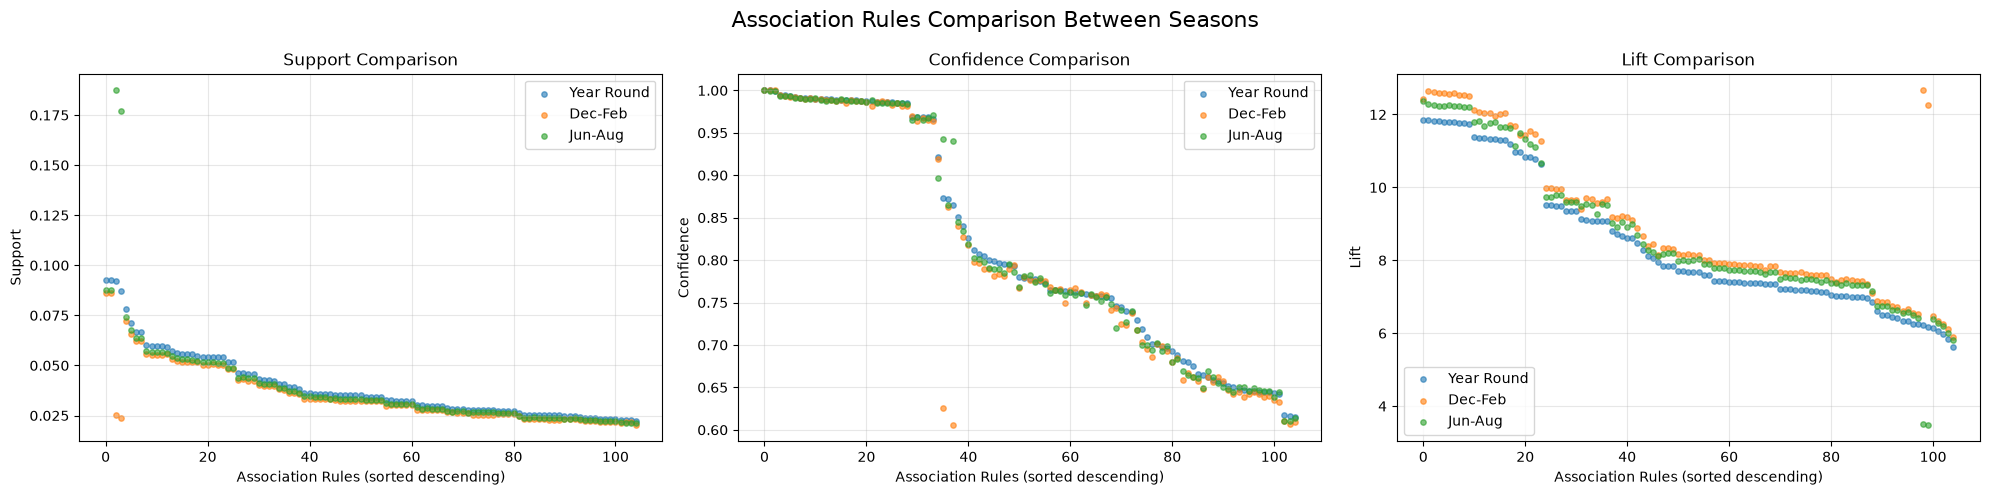

In [42]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

datasets = [
    (support_compt, 'support', 'Support'),
    (confidence_comp, 'confidence', 'Confidence'),
    (lift_comp, 'lift', 'Lift')
]

for ax, (df, metric, title) in zip(axes, datasets):

    ax.scatter(df.index, df[f'{metric}_x'], label='Year Round', alpha=0.6, s=15)
    ax.scatter(df.index, df[f'{metric}_y'], label='Dec-Feb', alpha=0.6, s=15)
    ax.scatter(df.index, df[metric], label='Jun-Aug', alpha=0.6, s=15)

    ax.set_title(f'{title} Comparison')
    ax.set_xlabel('Association Rules (sorted descending)')
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Association Rules Comparison Between Seasons', fontsize=16)
plt.tight_layout()
plt.show()

The visualization shows that most common association rules maintain similar Support, Confidence, and Lift values across seasons, with a few outliers indicating noticeable seasonal variations in these metrics.

#### Show at least one rule that exists in one season and disappears entirely in the other.

Comnparing Jun-Aug to Dec-Feb

In [72]:
rules_disappeared = (
    rules_jun_aug
    .merge(rules_dec_feb, on=['antecedents', 'consequents'], how='left', indicator=True)
    .query("_merge == 'left_only'")
    .drop(columns=['_merge'])
)



In [74]:
rules_disappeared = rules_disappeared[['antecedents', 'consequents', 'support_x', 'confidence_x', 'lift_x']].sort_values(by='lift_x', ascending=False).reset_index(drop=True)
rules_disappeared[rules_disappeared['consequents'].apply(lambda x: len(x.split(', ')) == 1)]

,antecedents,consequents,support_x,confidence_x,lift_x
3,"Bacon, Farine tout usage, Bananes",Sirop d'érable,0.005026,0.998426,13.816208
4,"Bacon, Oeufs, Crème 35%",Sirop d'érable,0.005201,0.952830,13.185248
5,"Beurre d'arachide, Frites surgelées, Sauce à p...",Fromage en grains,0.005054,0.992224,12.391094
6,"Frites surgelées, Noix mélangées, Sauce à poutine",Fromage en grains,0.005244,0.991760,12.385304
7,"Bacon, Bananes, Sirop d'érable",Farine tout usage,0.005026,0.568803,12.094326
...,...,...,...,...,...
8587,"Bière, Savon à vaisselle",Pain à hamburger,0.014065,0.506779,2.689689
8588,"Bière, Moutarde de Dijon",Pain à hamburger,0.007831,0.506144,2.686321
8589,"Bière, Pommes",Pain à hamburger,0.008646,0.505910,2.685075
8590,"Bière, Chocolat noir",Pain à hamburger,0.006912,0.502447,2.666700


One association rule with a high lift (12.19) that appears in Jun–Aug but disappears in Dec–Feb is the combination of *Bananes*,*Bacon*, and *Farine tout usage* leading to *Sirop d'érable*. This rule has a confidence of 51% and a lift of 10.95, indicating a strong association between these products.

#### Conclude

If the website uses year-round association rules in January, the top 5 recommended items may not match the top 5 most strongly associated items for that season. Some rules may even do not exist from the winter results, as customer purchasing behavior can change across seasons. As a result, the recommendations may be less relevant to customers during January.

### Final Conclusion and Decisions before creating rules.

Based on the association rule mining and seasonal analysis, the following decisions were made to improve the recommendation system's performance and relevance.

#### Key Findings and Decisions

- **Product exclusion:** *Sac réutilisable* was removed from the initial dataset to avoid misleading and unnecessary rules, while potentially reducing computational load.
- **Confidence threshold:** Only rules with confidence of at least 60% will be considered.
- **Single-item recommendation:** The consequent must contain only one product, since the application will recommend one item at a time.
- **Seasonal differences:** Some rules disappear between seasons, while others show changes in support, confidence, and lift.
- **Rule ranking:** The top 10 rules ranked by lift change across seasons, showing differences in customer purchasing behavior.
- **Common rules:** Most rules shared across seasons maintain similar support, confidence, and lift values, with some exceptions.

#### Final Model Configuration

The recommendation system will use **four seasonal rule sets**, allowing recommendations to adapt to changes in customer purchasing behavior throughout the year.

| Parameter | Final Decision |
|---|---|
| Minimum support | 0.02 (2%) |
| Minimum confidence | 0.60 (60%) |
| Lift | Greater than 1 |
| Consequent size | Exactly 1 product |
| Recommendation output | 1 product selected from the top 5 matching candidates |
| Seasonal periods | Dec–Feb, Mar–May, Jun–Aug, Sep–Nov |
| Excluded product | Sac réutilisable |

#### Conclusion

The analysis confirmed that **seasonality influences association rules**, making seasonal mining more appropriate than relying only on year-round patterns. The final approach will generate separate rules for each season and rank matching recommendations using lift.

For each customer basket, the application will identify the top five eligible recommendations and suggest one product. This approach aims to provide more relevant recommendations while avoiding trivial associations and controlling Apriori's computational cost.

## Phase 5 — Save the rules (separate offline from online)

The rules will be created by season.

### Spliting data by season

In [45]:
## Getting dataset
## My target is run from this point to create the final rules

tdf = pd.read_csv("../data/products.zip")

new_dataset = tdf[tdf['Item']!='Sac réutilisable'].copy()
new_dataset['month'] = pd.to_datetime(new_dataset['Date'], errors='coerce').dt.month_name()



In [46]:
## Creating dataset by season
dec_feb_dataset = new_dataset[new_dataset['month'].isin(['December', 'January', 'February'])].copy()
mar_may_dataset = new_dataset[new_dataset['month'].isin(['March', 'April', 'May'])].copy()
jun_aug_dataset = new_dataset[new_dataset['month'].isin(['June', 'July', 'August'])].copy()
sep_nov_dataset = new_dataset[new_dataset['month'].isin(['September', 'October', 'November'])].copy()

### Creating rules by season

#### December to February

In [47]:
basket_dec_feb = (dec_feb_dataset.groupby('TransactionID')['Item'].apply(lambda items: sorted(set(items))).tolist())

te=TransactionEncoder()
te_ary = te.fit(basket_dec_feb).transform(basket_dec_feb)
df_dec_feb = pd.DataFrame(te_ary, columns=te.columns_)


In [48]:
df_dec_feb_top_item = df_dec_feb.sum().sort_values(ascending=False).head(1)
df_dec_feb_top_item.index[0]

'Croustilles'

In [49]:
frequent_itemsets_dec_feb = apriori(df_dec_feb,
                            min_support=0.005,
                            use_colnames=True,
                            low_memory=True
                            )

rules_dec_feb = association_rules(frequent_itemsets_dec_feb, metric="confidence", min_threshold=0.5)


rules_dec_feb = rules_dec_feb[cols]
rules_dec_feb['antecedents'] = rules_dec_feb['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_dec_feb['consequents'] = rules_dec_feb['consequents'].apply(lambda x: ', '.join(list(x)))

In [50]:
rules_dec_feb.insert(0, 'season', 'Dec-Feb')

#### March to May

In [51]:
basket_mar_may = (mar_may_dataset.groupby('TransactionID')['Item'].apply(lambda items: sorted(set(items))).tolist())

te=TransactionEncoder()
te_ary = te.fit(basket_mar_may).transform(basket_mar_may)
df_mar_may = pd.DataFrame(te_ary, columns=te.columns_)

In [52]:
frequent_itemsets_mar_may = apriori(df_mar_may,
                            min_support=0.005,
                            use_colnames=True,
                            low_memory=True
                            )

rules_mar_may = association_rules(frequent_itemsets_mar_may, metric="confidence", min_threshold=0.5)


rules_mar_may = rules_mar_may[cols]
rules_mar_may['antecedents'] = rules_mar_may['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_mar_may['consequents'] = rules_mar_may['consequents'].apply(lambda x: ', '.join(list(x)))


In [53]:
rules_mar_may.insert(0, 'season', 'Mar-May')

#### June to August

In [54]:
basket_jun_aug = (jun_aug_dataset.groupby('TransactionID')['Item'].apply(lambda items: sorted(set(items))).tolist())

te=TransactionEncoder()
te_ary = te.fit(basket_jun_aug).transform(basket_jun_aug)
df_jun_aug = pd.DataFrame(te_ary, columns=te.columns_)

In [55]:
frequent_itemsets_jun_aug = apriori(df_jun_aug,
                            min_support=0.005,
                            use_colnames=True,
                            low_memory=True
                            )

rules_jun_aug = association_rules(frequent_itemsets_jun_aug, metric="confidence", min_threshold=0.5)


rules_jun_aug = rules_jun_aug[cols]
rules_jun_aug['antecedents'] = rules_jun_aug['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_jun_aug['consequents'] = rules_jun_aug['consequents'].apply(lambda x: ', '.join(list(x)))


In [56]:
rules_jun_aug.insert(0, 'season', 'Jun-Aug')

#### September to November

In [57]:
basket_sep_nov = (sep_nov_dataset.groupby('TransactionID')['Item'].apply(lambda items: sorted(set(items))).tolist())

te=TransactionEncoder()
te_ary = te.fit(basket_sep_nov).transform(basket_sep_nov)
df_sep_nov = pd.DataFrame(te_ary, columns=te.columns_)

In [58]:
frequent_itemsets_sep_nov = apriori(df_sep_nov,
                            min_support=0.005,
                            use_colnames=True,
                            low_memory=True
                            )

rules_sep_nov = association_rules(frequent_itemsets_sep_nov, metric="confidence", min_threshold=0.5)


rules_sep_nov = rules_sep_nov[cols]
rules_sep_nov['antecedents'] = rules_sep_nov['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_sep_nov['consequents'] = rules_sep_nov['consequents'].apply(lambda x: ', '.join(list(x)))


In [59]:
rules_sep_nov.insert(0, 'season', 'Sep-Nov')

#### Aggregating Season Rules

In [60]:
final_rules = pd.concat(
    [rules_dec_feb, rules_mar_may, rules_jun_aug, rules_sep_nov]
    , ignore_index=True
    )

final_rules = final_rules[final_rules['lift'] > 1.0].sort_values(by='lift', ascending=False)  ## Saving only rules with lift greater than 1.0

final_rules=final_rules[final_rules['consequents'].apply(lambda x: len(x.split(', ')) == 1)]  ## Keeping only rules with a single consequent

final_rules=final_rules[['season', 'antecedents', 'consequents', 'support', 'confidence', 'lift']]

In [61]:
def season(season):
    if season == 'Dec-Feb':
        return 'Winter'
    elif season == 'Mar-May':
        return 'Spring'
    elif season == 'Jun-Aug':
        return 'Summer'
    elif season == 'Sep-Nov':
        return 'Fall'
    else:
        return 'Unknown'

In [62]:
final_rules.insert(
    0,
    'season_name',
    final_rules['season'].apply(season)

)

In [63]:
final_rules

,season_name,season,antecedents,consequents,support,confidence,lift
2176,Winter,Dec-Feb,"Pain à hamburger, Ketchup, Steak de boeuf",Charbon de bois,0.010123,1.000000,20.243033
2652,Winter,Dec-Feb,"Bière, Ketchup, Pain à hamburger, Steak de boeuf",Charbon de bois,0.005402,1.000000,20.243033
2194,Winter,Dec-Feb,"Sauce BBQ, Ketchup, Steak de boeuf",Charbon de bois,0.007540,1.000000,20.243033
2759,Winter,Dec-Feb,"Pain à hamburger, Ketchup, Saucisses, Steak de...",Charbon de bois,0.005531,1.000000,20.243033
2749,Winter,Dec-Feb,"Sauce BBQ, Ketchup, Pain à hamburger, Steak de...",Charbon de bois,0.005199,1.000000,20.243033
...,...,...,...,...,...,...,...
8123,Summer,Jun-Aug,"Bière, Savon à vaisselle",Pain à hamburger,0.014065,0.506779,2.689689
8087,Summer,Jun-Aug,"Bière, Moutarde de Dijon",Pain à hamburger,0.007831,0.506144,2.686321
8112,Summer,Jun-Aug,"Bière, Pommes",Pain à hamburger,0.008646,0.505910,2.685075
8013,Summer,Jun-Aug,"Bière, Chocolat noir",Pain à hamburger,0.006912,0.502447,2.666700


### Saving final rules


In [64]:
final_rules.to_json('../models/rules.json',orient='records',indent=4)
final_rules.to_csv('../models/rules.csv',index=False)

### Saving most popular item by session


In [65]:
df_dec_feb

,Ail,Algues nori,Avocat,Bacon,Bagels,Baguette,Bananes,Beurre,Beurre d'arachide,Biscuits,...,Sucre blanc,Thon en conserve,Thé vert,Tomates,Tortillas,Vin blanc,Vin rouge,Vinaigre balsamique vieilli,Wasabi,Yogourt grec
0,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,False,False,False,False,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
246960,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,True,False,False,False,False
246961,False,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
246962,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,True
246963,False,False,False,False,False,False,False,False,False,True,...,True,False,False,False,False,False,False,False,False,False


In [66]:
df_dec_feb_top_item = df_dec_feb.sum().sort_values(ascending=False).head(10).reset_index().rename(columns={'index': 'item', 0: 'count'})
df_mar_may_top_item = df_mar_may.sum().sort_values(ascending=False).head(10).reset_index().rename(columns={'index': 'item', 0: 'count'})
df_jun_aug_top_item = df_jun_aug.sum().sort_values(ascending=False).head(10).reset_index().rename(columns={'index': 'item', 0: 'count'})
df_sep_nov_top_item = df_sep_nov.sum().sort_values(ascending=False).head(10).reset_index().rename(columns={'index': 'item', 0: 'count'})

df_dec_feb_top_item.insert(0, "season", "Dec_Feb")
df_dec_feb_top_item.insert(0,'season_name','Winter')
df_mar_may_top_item.insert(0, "season", "Mar_May")
df_mar_may_top_item.insert(0,'season_name','Spring')
df_jun_aug_top_item.insert(0, "season", "Jun_Aug")
df_jun_aug_top_item.insert(0,'season_name','Summer')
df_sep_nov_top_item.insert(0, "season", "Sep_Nov")
df_sep_nov_top_item.insert(0,'season_name','Autumn')


popular_items_by_session_df = pd.concat([
    df_dec_feb_top_item,
    df_mar_may_top_item,
    df_jun_aug_top_item,
    df_sep_nov_top_item
], ignore_index=True)

popular_items_by_session_df.to_csv("../data/popular_items_by_session.csv", index=False)

### Saving Metadata

In [67]:
## Calculating coverage of the final rules
nb_unique_items = tdf['Item'].nunique()
coverage = final_rules['consequents'].nunique()
coverage = round(coverage / nb_unique_items, 4)
print(nb_unique_items)
print(coverage)

98
0.3878


In [68]:
## Calculating coverage per season
coverage = {}
nb_unique_items = tdf['Item'].nunique()
for season in ['Winter', 'Spring', 'Summer', 'Fall']:
    coverage[season] = round(final_rules[final_rules['season_name']== season]['consequents'].nunique() / nb_unique_items, 4)
coverage['Average'] = round(sum(coverage[season] for season in ['Winter', 'Spring', 'Summer', 'Fall']) / 4, 4)

In [69]:
metadata ={
    'mining_date': pd.Timestamp.now().date().strftime('%Y-%m-%d'),
    'min_support': 0.005,
    'confidence': 0.5,
    'lift': 'greater than 1.0',
    'number_of_total_rules': len(final_rules),
    'num_winter_rules': len(final_rules[final_rules['season_name'] == 'Winter']),
    'num_spring_rules': len(final_rules[final_rules['season_name'] == 'Spring']),
    'num_summer_rules': len(final_rules[final_rules['season_name'] == 'Summer']),
    'num_fall_rules': len(final_rules[final_rules['season_name'] == 'Fall']),
    'coverage': coverage
}

In [70]:
metadata

{'mining_date': '2026-11-06',
 'min_support': 0.005,
 'confidence': 0.5,
 'lift': 'greater than 1.0',
 'number_of_total_rules': 16808,
 'num_winter_rules': 2359,
 'num_spring_rules': 3574,
 'num_summer_rules': 7878,
 'num_fall_rules': 2997,
 'coverage': {'Winter': 0.3776,
  'Spring': 0.3673,
  'Summer': 0.3265,
  'Fall': 0.3673,
  'Average': 0.3597}}

In [71]:
with open("../models/metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

### Rules and Metada Conclusion  

The association rules were successfully saved in `models/rules.json`, with their configuration and coverage recorded in `models/metadata.json`.

#### Final Results

| Metric | Value |
|---|---|
| Mining date | November 4, 2026 |
| Minimum support | 0,5% |
| Minimum confidence | 50% |
| Lift | Greater than 1 |
| Total rules | 16,808 |
| Product coverage | 38.78% |

#### Rules by Season

| Season | Number of Rules |
|---|---:|
| Winter (Dec–Feb) | 2823 |
| Spring (Mar–May) | 4489 |
| Summer (Jun–Aug) | 10523 |
| Autumn (Sep–Nov) | 3739 |
| **Total** | **16,808** |

#### Conclusion

The final seasonal models generated **16,808 association rules**, with product coverage of **38.78%**. Summer produced the highest number of rules, while winter produced the fewest, reinforcing the importance of seasonal analysis.
